# 🎬 Movie Recommendation System
**Neural Collaborative Filtering (NCF)** on the **MovieLens 20M** dataset — TensorFlow / Keras.

*Authors: Aya Aburahmeh · Hala AlJafary*

**Pipeline:** 1. Setup → 2. Load data → 3. Preprocessing → 4. Model → 5. Training → 6. Evaluation → 7. Recommendations → 8. Save model

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

In [2]:
# ---- Paths (change these to where you saved the MovieLens 20M files) ----
RATINGS_PATH = "rating.csv"
MOVIES_PATH = "movie.csv"
MODEL_PATH = "my_final_ncf_model.keras"

# ---- Preprocessing settings ----
MIN_RATINGS_PER_USER = 50
MIN_RATINGS_PER_MOVIE = 10
TRAIN_RATIO = 0.8

# ---- Model / training settings ----
EMBEDDING_SIZE = 32
LEARNING_RATE = 0.0005
BATCH_SIZE = 2048
EPOCHS = 10

## 2. Load Data

In [3]:
df = pd.read_csv(RATINGS_PATH)

In [4]:
df.head()

,userId,movieId,rating,timestamp
0,1,2,3.5,2005-04-02 23:53:47
1,1,29,3.5,2005-04-02 23:31:16
2,1,32,3.5,2005-04-02 23:33:39
3,1,47,3.5,2005-04-02 23:32:07
4,1,50,3.5,2005-04-02 23:29:40


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000263 entries, 0 to 20000262
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  object 
dtypes: float64(1), int64(2), object(1)
memory usage: 610.4+ MB


In [6]:
df.shape

(20000263, 4)

In [7]:
print(df.isnull().sum())

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


## 3. Preprocessing

### 3.1 Remove duplicates
Keep only the most recent rating for each user–movie pair.

In [8]:
df.drop_duplicates(subset=['userId', 'movieId'], keep='last', inplace=True)

In [9]:
df.shape

(20000263, 4)

### 3.2 Filter sparse users and movies

In [10]:
user_counts = df.groupby('userId').size()
active_users = user_counts[user_counts >= MIN_RATINGS_PER_USER].index
df = df[df['userId'].isin(active_users)]

movie_counts = df.groupby('movieId').size()
popular_movies = movie_counts[movie_counts >= MIN_RATINGS_PER_MOVIE].index
df = df[df['movieId'].isin(popular_movies)]

print("New Shape:", df.shape)

New Shape: (18300248, 4)


### 3.3 Normalize ratings to [0, 1] (Min-Max)

In [11]:
min_rating = df['rating'].min()
max_rating = df['rating'].max()

df['rating'] = (df['rating'] - min_rating) / (max_rating - min_rating)

print("Ratings scaled to [0, 1]")

Ratings scaled to [0, 1]


### 3.4 Sort by time and encode IDs
User and movie IDs are mapped to sequential integers (needed by the embedding layers).

In [12]:
df = df.sort_values(by='timestamp')

user_ids = df['userId'].unique().tolist()
user2user_encoded = {x: i for i, x in enumerate(user_ids)}
movie_ids = df['movieId'].unique().tolist()
movie2movie_encoded = {x: i for i, x in enumerate(movie_ids)}

df['user'] = df['userId'].map(user2user_encoded)
df['movie'] = df['movieId'].map(movie2movie_encoded)

num_users = len(user_ids)
num_movies = len(movie_ids)

print(f"Total Unique Users: {num_users}")
print(f"Total Unique Movies: {num_movies}")

Total Unique Users: 85307
Total Unique Movies: 15359


### 3.5 Chronological train / test split
The oldest 80% of ratings are used for training and the newest 20% for testing, to avoid data leakage.

In [13]:
cutoff = int(TRAIN_RATIO * len(df))

train_df = df.iloc[:cutoff]
test_df = df.iloc[cutoff:]

print(f"Training on: {len(train_df)} samples")
print(f"Testing on: {len(test_df)} samples")

Training on: 14640198 samples
Testing on: 3660050 samples


## 4. Model — Neural Collaborative Filtering

```
User  → Embedding(32) → Flatten ─┐
                                 ├→ Concatenate(64) → Dense(64, ReLU) → Dropout(0.5)
Movie → Embedding(32) → Flatten ─┘                  → Dense(32, ReLU) → Dropout(0.3)
                                                    → Dense(1, Sigmoid)
```

In [14]:
def build_refined_model(num_users, num_movies, embedding_size=EMBEDDING_SIZE):
    user_input = layers.Input(shape=(1,))
    movie_input = layers.Input(shape=(1,))

    user_emb = layers.Embedding(
        num_users, embedding_size,
        embeddings_initializer="he_normal",
        embeddings_regularizer=regularizers.l2(1e-5)
    )(user_input)

    movie_emb = layers.Embedding(
        num_movies, embedding_size,
        embeddings_initializer="he_normal",
        embeddings_regularizer=regularizers.l2(1e-5)
    )(movie_input)

    user_vec = layers.Flatten()(user_emb)
    movie_vec = layers.Flatten()(movie_emb)

    concat = layers.Concatenate()([user_vec, movie_vec])

    x = layers.Dense(64, activation="relu")(concat)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    output = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs=[user_input, movie_input], outputs=output)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=[tf.keras.metrics.RootMeanSquaredError()]
    )
    return model


ncf_model = build_refined_model(num_users, num_movies)

## 5. Training

In [15]:
# EarlyStopping: stop training when val_loss stops improving (and restore the best weights).
# ReduceLROnPlateau: lower the learning rate when val_loss stalls.
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        patience=2,
        restore_best_weights=True,
        monitor='val_loss'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        factor=0.2,
        patience=1,
        min_lr=1e-6,
        monitor='val_loss'
    )
]

history = ncf_model.fit(
    x=[train_df['user'], train_df['movie']],
    y=train_df['rating'],
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=([test_df['user'], test_df['movie']], test_df['rating']),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
7149/7149 ━━━━━━━━━━━━━━━━━━━━ 579s 80ms/step - loss: 0.0409 - root_mean_squared_error: 0.1959 - val_loss: 0.0454 - val_root_mean_squared_error: 0.2066 - learning_rate: 5.0000e-04
Epoch 2/10
7149/7149 ━━━━━━━━━━━━━━━━━━━━ 449s 63ms/step - loss: 0.0386 - root_mean_squared_error: 0.1899 - val_loss: 0.0450 - val_root_mean_squared_error: 0.2062 - learning_rate: 5.0000e-04
Epoch 3/10
7149/7149 ━━━━━━━━━━━━━━━━━━━━ 453s 63ms/step - loss: 0.0379 - root_mean_squared_error: 0.1886 - val_loss: 0.0447 - val_root_mean_squared_error: 0.2060 - learning_rate: 5.0000e-04
Epoch 4/10
7149/7149 ━━━━━━━━━━━━━━━━━━━━ 457s 64ms/step - loss: 0.0376 - root_mean_squared_error: 0.1882 - val_loss: 0.0446 - val_root_mean_squared_error: 0.2061 - learning_rate: 5.0000e-04
Epoch 5/10
7149/7149 ━━━━━━━━━━━━━━━━━━━━ 452s 63ms/step - loss: 0.0357 - root_mean_squared_error: 0.1848 - val_loss: 0.0437 - val_root_mean_squared_error: 0.2056 - learning_rate: 1.0000e-04
Epoch 6/10
7149/7149 ━━━━━━━━━━━━━━━━━━━━ 460

## 6. Evaluation

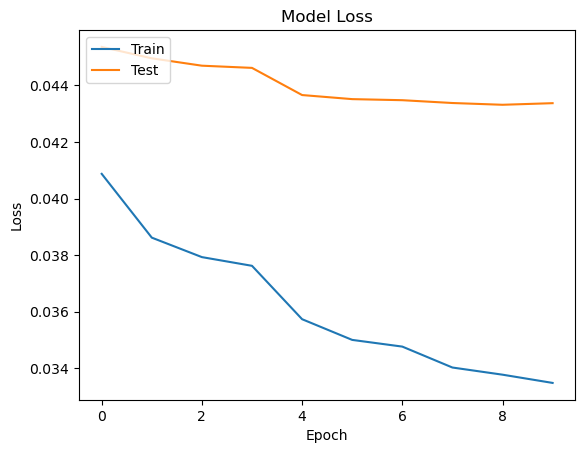

In [16]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Model Loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Train", "Test"], loc="upper left")
plt.show()

In [17]:
loss, rmse = ncf_model.evaluate([test_df['user'], test_df['movie']], test_df['rating'])

print(f"Final Test RMSE: {rmse}")

114377/114377 ━━━━━━━━━━━━━━━━━━━━ 914s 8ms/step - loss: 0.0433 - root_mean_squared_error: 0.2057
Final Test RMSE: 0.20566734671592712


## 7. Recommendations

In [18]:
movies_metadata = pd.read_csv(MOVIES_PATH)
movies_metadata.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [19]:
def show_recommendations_v2(user_id_original):
    # Convert the original user ID to the model's index
    user_idx = user2user_encoded[user_id_original]

    # Movies the user has already watched (original IDs)
    watched_movie_ids = df[df['userId'] == user_id_original]['movieId'].unique()

    # All available movies (original IDs)
    all_movie_ids = np.array(list(movie2movie_encoded.keys()))

    # Keep only the movies the user has NOT watched
    not_watched_movie_ids = np.setdiff1d(all_movie_ids, watched_movie_ids)

    # Convert those movies to model indices
    not_watched_encoded = np.array([movie2movie_encoded[m] for m in not_watched_movie_ids])

    # Predict ratings
    user_input = np.array([user_idx] * len(not_watched_encoded))
    predictions = ncf_model.predict([user_input, not_watched_encoded], batch_size=10000)

    # Take the top 10
    top_indices = predictions.flatten().argsort()[-10:][::-1]
    final_ids = not_watched_movie_ids[top_indices]

    # Look up the titles
    recommendations = movies_metadata[movies_metadata['movieId'].isin(final_ids)]

    print(f"\n--- Top 10 Recommended Movies for User {user_id_original} ---")
    return recommendations[['title', 'genres']]

In [20]:
user_id_test = 1  # same user used above

print(f"--- Movies User {user_id_test} actually rated highest (ground truth) ---")
top_real = df[df['userId'] == user_id_test].sort_values(by='rating', ascending=False).head(5)
real_movie_ids = top_real['movieId'].values
print(movies_metadata[movies_metadata['movieId'].isin(real_movie_ids)][['title', 'genres']])

print("\n" + "=" * 50 + "\n")

print("--- Movies the model recommends for the same user (prediction) ---")
print(show_recommendations_v2(user_id_test))

--- Movies User 1 actually rated highest (ground truth) ---
                                                  title  \
1171  Star Wars: Episode V - The Empire Strikes Back...   
4897  Lord of the Rings: The Fellowship of the Ring,...   
5853      Lord of the Rings: The Two Towers, The (2002)   
7041  Lord of the Rings: The Return of the King, The...   
7860                                      Freaks (1932)   

                              genres  
1171         Action|Adventure|Sci-Fi  
4897               Adventure|Fantasy  
5853               Adventure|Fantasy  
7041  Action|Adventure|Drama|Fantasy  
7860              Crime|Drama|Horror  


--- Movies the model recommends for the same user (prediction) ---
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

--- Top 10 Recommended Movies for User 1 ---
                                            title  \
108                             Braveheart (1995)   
352                           Forrest Gump (1994)   
523                       Schindler's L

## 8. Save the Model

In [21]:
ncf_model.save(MODEL_PATH)
print("Model saved!")

Model saved!
